 Analyzing NIFTY 500 (long)...
 Analyzing NIFTY 500 (broad)...
 Analyzing S&P 500 (long)...
 Analyzing S&P 500 (broad)...

 FINAL PERFORMANCE DASHBOARD (NET OF COSTS)


,Market,Cohort,Strategy,Pair,ROI,Sharpe,Max_Drawdown
0,NIFTY 500,long,Traditional,ACE.NS-ELECON.NS,485.346,0.913,-31.596
1,NIFTY 500,long,Proposed ML,AXISBANK.NS-HDFCBANK.NS,8.605,0.367,-31.103
2,NIFTY 500,broad,Traditional,ACE.NS-ELECON.NS,26.412,0.869,-31.217
3,NIFTY 500,broad,Proposed ML,INDHOTEL.NS-EIHOTEL.NS,19.648,1.090,-21.268
4,S&P 500,long,Traditional,A-PLD,6.961,0.440,-36.147
5,S&P 500,long,Proposed ML,DG-DLTR,7.987,0.583,-45.656
6,S&P 500,broad,Traditional,ADI-DOV,1.993,0.424,-23.947
7,S&P 500,broad,Proposed ML,DG-DLTR,2.749,0.479,-45.655


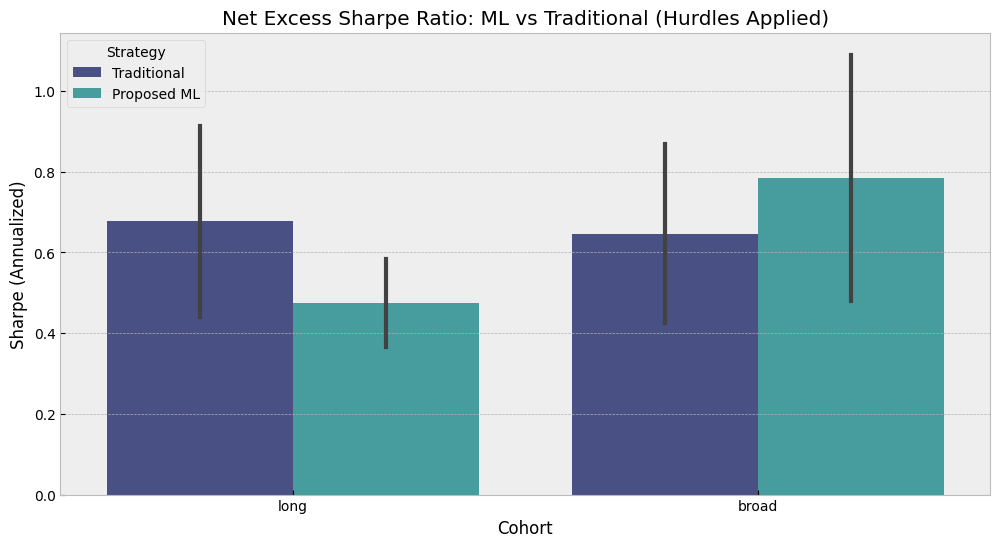

In [2]:
import sys
import pandas as pd
import numpy as np
import warnings
import importlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# -----------------------------
# 1. INITIAL SETUP
# -----------------------------
warnings.filterwarnings('ignore')
plt.style.use("bmh")

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Force reload the backtester to ensure 15bps fees & RFR logic are active
import src.backtester
importlib.reload(src.backtester)
from src.backtester import VectorizedBacktester

DATA_PROCESSED = project_root / "data_processed"

# -----------------------------
# 2. LOAD DATASETS
# -----------------------------
trad_file = DATA_PROCESSED / "traditional_benchmark_strict.csv"
ml_file = DATA_PROCESSED / "all_ml_pairs.csv"

if not trad_file.exists() or not ml_file.exists():
    raise FileNotFoundError(" Required data files missing. Ensure Notebooks 04 and 05 were run.")

df_verified_trad = pd.read_csv(trad_file)
df_ml = pd.read_csv(ml_file)

# -----------------------------
# 3. COMPARISON LOGIC
# -----------------------------
def run_comparison():
    scenarios = [
        ("NIFTY 500", "long", "nifty500_prices.parquet"),
        ("NIFTY 500", "broad", "nifty500_2015_prices.parquet"),
        ("S&P 500", "long", "sp500_prices.parquet"),
        ("S&P 500", "broad", "sp500_2015_prices.parquet"),
    ]

    final_metrics = []

    for market, cohort, price_file in scenarios:
        print(f" Analyzing {market} ({cohort})...")
        
        price_data_path = DATA_PROCESSED / price_file
        if not price_data_path.exists(): continue
        
        prices = pd.read_parquet(price_data_path)
        
        # --- INITIALIZE BULLETPROOF BACKTESTER ---
        m_key = "NIFTY" if "NIFTY" in market.upper() else "SPX"
        bt = VectorizedBacktester(
            prices, 
            market=m_key, 
            entry_z=2.0, 
            stop_loss=-0.05, 
            take_profit=0.15
        )

        # A. TRADITIONAL PERFORMANCE
        trad_row = df_verified_trad[(df_verified_trad['Market'] == market) & (df_verified_trad['Cohort'] == cohort)]
        if not trad_row.empty:
            res_t = bt.run_pair_backtest(trad_row.iloc[0]['Ticker1'], trad_row.iloc[0]['Ticker2'])
            if res_t:
                final_metrics.append({
                    "Market": market, "Cohort": cohort, "Strategy": "Traditional",
                    "Pair": f"{res_t['ticker1']}-{res_t['ticker2']}",
                    "ROI": res_t['ROI'], "Sharpe": res_t['Sharpe'], "Max_Drawdown": res_t['Max_Drawdown']
                })

        # B. ML PERFORMANCE
        ml_subset = df_ml[(df_ml['Market'] == market) & (df_ml['Cohort'] == cohort)]
        best_ml_res = None
        best_ml_sharpe = -np.inf

        for cid in ml_subset['Cluster_ID'].unique():
            members = ml_subset[ml_subset['Cluster_ID'] == cid]['Ticker'].tolist()
            results = bt.test_cluster(members)
            if not results.empty:
                top = results.iloc[0]
                if top['Sharpe'] > best_ml_sharpe:
                    best_ml_sharpe = top['Sharpe']
                    best_ml_res = top

        # FIXED TRUTH VALUE CHECK
        if best_ml_res is not None:
            final_metrics.append({
                "Market": market, "Cohort": cohort, "Strategy": "Proposed ML",
                "Pair": f"{best_ml_res['ticker1']}-{best_ml_res['ticker2']}",
                "ROI": best_ml_res['ROI'], "Sharpe": best_ml_res['Sharpe'], "Max_Drawdown": best_ml_res['Max_Drawdown']
            })

    return pd.DataFrame(final_metrics)

# -----------------------------
# 4. EXECUTION & DISPLAY
# -----------------------------
df_results = run_comparison()

if df_results is not None and not df_results.empty:
    print("\n FINAL PERFORMANCE DASHBOARD (NET OF COSTS)")
    display(df_results.style.background_gradient(subset=['Sharpe'], cmap='RdYlGn').format(precision=3))

    # Final Visualization
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_results, x='Cohort', y='Sharpe', hue='Strategy', palette='mako')
    plt.title("Net Excess Sharpe Ratio: ML vs Traditional (Hurdles Applied)")
    plt.ylabel("Sharpe (Annualized)")
    plt.show()
else:
    print(" No results found to display.")

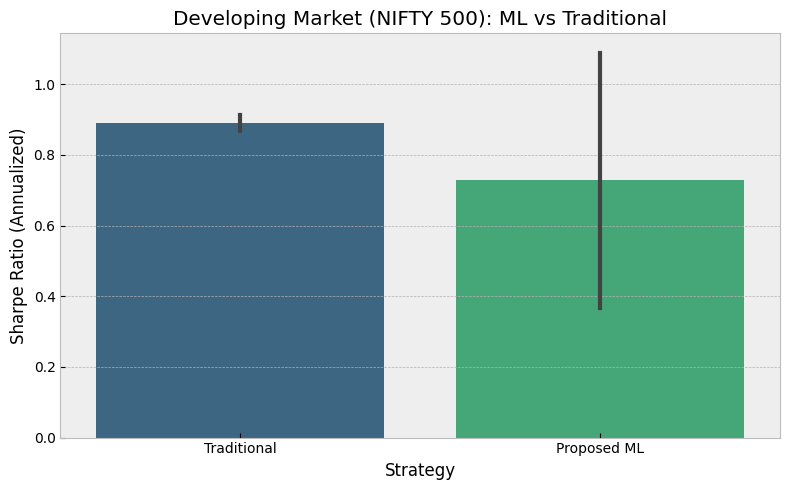

In [3]:
# ---------------------------------------------
# DEVELOPING MARKET – NIFTY 500
# ---------------------------------------------
df_nifty = df_results[df_results["Market"] == "NIFTY 500"]

plt.figure(figsize=(8,5))
sns.barplot(
    data=df_nifty,
    x='Strategy',
    y='Sharpe',
    palette='viridis'
)

plt.title("Developing Market (NIFTY 500): ML vs Traditional")
plt.ylabel("Sharpe Ratio (Annualized)")
plt.xlabel("Strategy")
plt.tight_layout()
plt.show()

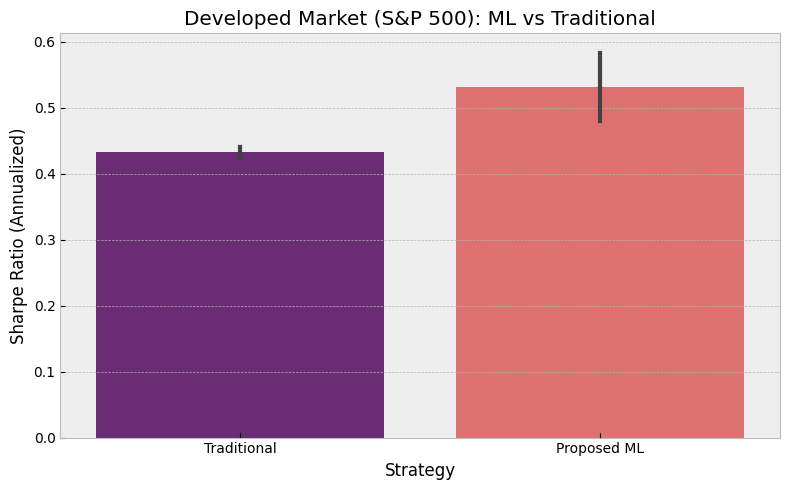

In [4]:
# ---------------------------------------------
# DEVELOPED MARKET – S&P 500
# ---------------------------------------------
df_sp = df_results[df_results["Market"] == "S&P 500"]

plt.figure(figsize=(8,5))
sns.barplot(
    data=df_sp,
    x='Strategy',
    y='Sharpe',
    palette='magma'
)

plt.title("Developed Market (S&P 500): ML vs Traditional")
plt.ylabel("Sharpe Ratio (Annualized)")
plt.xlabel("Strategy")
plt.tight_layout()
plt.show()

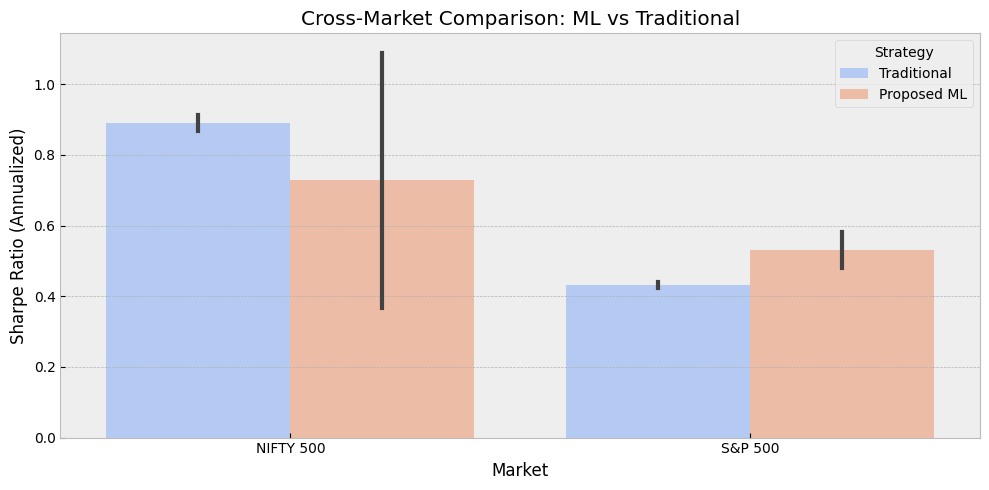

In [5]:
# ---------------------------------------------
# CROSS-MARKET STRATEGY COMPARISON
# ---------------------------------------------
plt.figure(figsize=(10,5))

sns.barplot(
    data=df_results,
    x='Market',
    y='Sharpe',
    hue='Strategy',
    palette='coolwarm'
)

plt.title("Cross-Market Comparison: ML vs Traditional")
plt.ylabel("Sharpe Ratio (Annualized)")
plt.xlabel("Market")
plt.legend(title="Strategy")
plt.tight_layout()
plt.show()

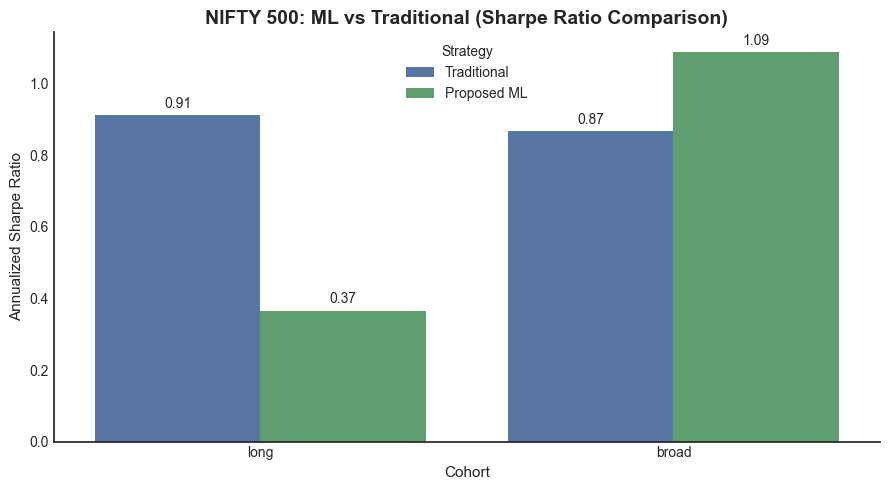

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.style.use("seaborn-v0_8-white")

def professional_market_plot(df_results, market_name):

    df_market = df_results[df_results["Market"] == market_name].copy()

    # Ensure ordering
    df_market["Cohort"] = pd.Categorical(df_market["Cohort"], 
                                         categories=["long","broad"],
                                         ordered=True)

    fig, ax = plt.subplots(figsize=(9,5))

    barplot = sns.barplot(
        data=df_market,
        x="Cohort",
        y="Sharpe",
        hue="Strategy",
        palette={"Traditional":"#4C72B0","Proposed ML":"#55A868"},
        ax=ax
    )

    # Title
    ax.set_title(f"{market_name}: ML vs Traditional (Sharpe Ratio Comparison)", 
                 fontsize=14, fontweight="bold")

    ax.set_ylabel("Annualized Sharpe Ratio", fontsize=11)
    ax.set_xlabel("Cohort", fontsize=11)
    ax.legend(title="Strategy", frameon=False)

    # Add value labels
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=3, fontsize=10)

    # Remove top/right spines
    sns.despine()

    plt.tight_layout()
    plt.show()

# Run for NIFTY
professional_market_plot(df_results, "NIFTY 500")

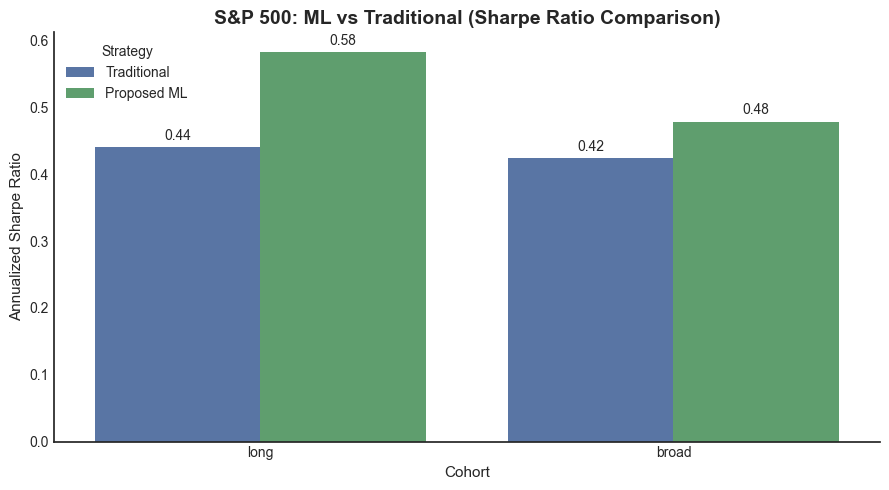

In [7]:
professional_market_plot(df_results, "S&P 500")

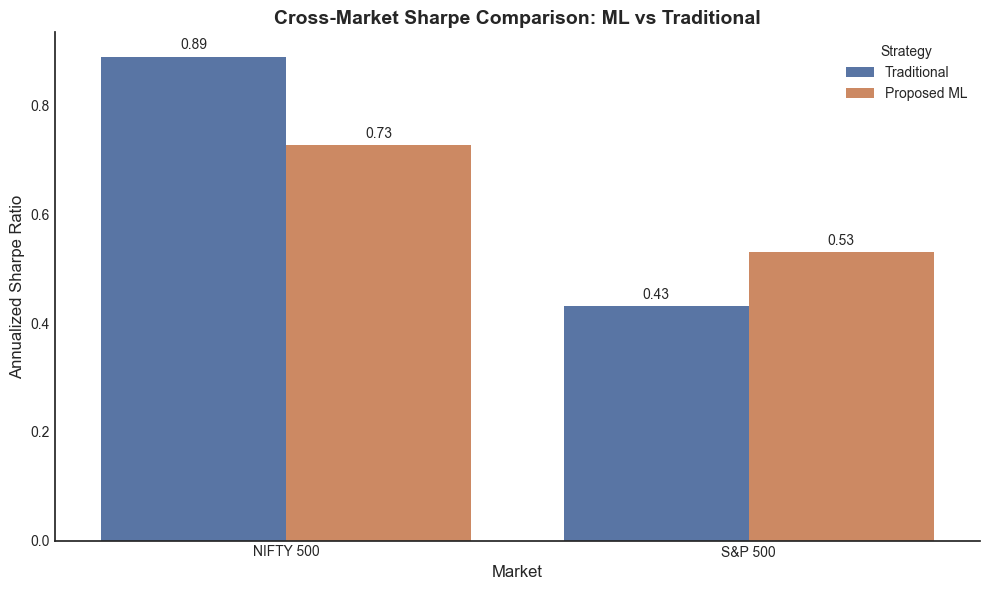

In [8]:
fig, ax = plt.subplots(figsize=(10,6))

sns.barplot(
    data=df_results,
    x="Market",
    y="Sharpe",
    hue="Strategy",
    ci=None,
    palette={"Traditional":"#4C72B0","Proposed ML":"#DD8452"},
    ax=ax
)

ax.set_title("Cross-Market Sharpe Comparison: ML vs Traditional", 
             fontsize=14, fontweight="bold")

ax.set_ylabel("Annualized Sharpe Ratio")
ax.legend(title="Strategy", frameon=False)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

In [9]:
if df_results is not None and not df_results.empty:

    print("\nFINAL PERFORMANCE DASHBOARD (NET OF COSTS)\n")

    # Clean column formatting
    styled_df = (
        df_results.style
        .format({
            "ROI": "{:.3f}",
            "Sharpe": "{:.3f}",
            "Max_Drawdown": "{:.3f}"
        })
        .set_properties(**{
            "text-align": "center",
            "white-space": "nowrap"
        })
        .set_table_styles([
            dict(selector="th", props=[("text-align", "center")])
        ])
        .background_gradient(subset=["Sharpe"], cmap="RdYlGn")
    )

    display(styled_df)


FINAL PERFORMANCE DASHBOARD (NET OF COSTS)



,Market,Cohort,Strategy,Pair,ROI,Sharpe,Max_Drawdown
0,NIFTY 500,long,Traditional,ACE.NS-ELECON.NS,485.346,0.913,-31.596
1,NIFTY 500,long,Proposed ML,AXISBANK.NS-HDFCBANK.NS,8.605,0.367,-31.103
2,NIFTY 500,broad,Traditional,ACE.NS-ELECON.NS,26.412,0.869,-31.217
3,NIFTY 500,broad,Proposed ML,INDHOTEL.NS-EIHOTEL.NS,19.648,1.090,-21.268
4,S&P 500,long,Traditional,A-PLD,6.961,0.440,-36.147
5,S&P 500,long,Proposed ML,DG-DLTR,7.987,0.583,-45.656
6,S&P 500,broad,Traditional,ADI-DOV,1.993,0.424,-23.947
7,S&P 500,broad,Proposed ML,DG-DLTR,2.749,0.479,-45.655
